# Example detections of all detectors on every dataset

Loads the results saved by `run_examples.py` and draws one panel per dataset (12 datasets → 4 × 3 grid):
the stream in light blue, one row per detector (KALEIDO on top), **TP** = circle at the window middle with the
window extent as a capped bar, **FP** = ×, **FN** = ▲ at the missed label, true drifts = dashed lines,
and the event week shaded for the operational data.

Run first (from the project root):
```
python run_examples.py --datasets all              # stream 0 of all 12 datasets
python run_examples.py --datasets all --ids 0 3 10 # several example streams per dataset
```

In [1]:
from pathlib import Path as _Path
import os as _os

for _candidate in (_Path.cwd(), *_Path.cwd().parents):
    if (_candidate / "KALEIDO_multi_instance.py").is_file() and (_candidate / "stable_windows.csv").is_file():
        _code_dir = _candidate
        break
    _nested = _candidate / "results_all_in_one_code"
    if (_nested / "KALEIDO_multi_instance.py").is_file() and (_nested / "stable_windows.csv").is_file():
        _code_dir = _nested
        break
else:
    raise FileNotFoundError("Could not locate results_all_in_one_code; start this notebook inside the repository")

_os.chdir(_code_dir)
(_code_dir / "figures").mkdir(exist_ok=True)
(_code_dir / "example_runs").mkdir(exist_ok=True)
import os, pickle
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

FEATURES = "gradient+season"                                   # same --features as run_examples.py
RESULTS  = f"../results_all_in_one_code/example_runs/example_runs_{FEATURES}.pkl"

with open(RESULTS, "rb") as f:
    all_runs = pickle.load(f)                                  # {"ts#id": {ts, id, stream, labels, event_length, title, results}}
print(len(all_runs), "example runs:", sorted(all_runs))

12 example runs: ['AR4_linear_1#0', 'AR4_nonlinear_1#0', 'friedman_2_drifts#0', 'friedman_5_drifts#0', 'friedman_no_drifts#0', 'infocom_4G_add_hour#0', 'infocom_4G_add_hour_trend#0', 'infocom_5G_add_hour#0', 'infocom_5G_add_hour_trend#0', 'random_easy#0', 'random_noisy#0', 'rolling_mean#0']


## Which panels, in which order, with which titles

In [2]:
DATASET_ORDER = ['infocom_4G_add_hour', 'infocom_4G_add_hour_trend', 'infocom_5G_add_hour', 'infocom_5G_add_hour_trend',
                 'AR4_linear_1', 'AR4_nonlinear_1', 'random_noisy', 'random_easy',
                 'rolling_mean', 'friedman_5_drifts', 'friedman_2_drifts', 'friedman_no_drifts']
DATASET_TITLES = {
    "AR4_linear_1":              "AR4 linear",
    "AR4_nonlinear_1":           "AR4 nonlinear",
    "friedman_2_drifts":         "Friedman 2 drifts",
    "friedman_5_drifts":         "Friedman 5 drifts",
    "friedman_no_drifts":        "Friedman no drifts",
    "infocom_4G_add_hour":       "Operational 4G",
    "infocom_4G_add_hour_trend": "Operational 4G trend",
    "infocom_5G_add_hour":       "Operational 5G",
    "infocom_5G_add_hour_trend": "Operational 5G trend",
    "random_easy":               "Random easy",
    "random_noisy":              "Random noisy",
    "rolling_mean":              "Rolling mean",
}
STREAM_ID = 0
DETECTOR_TITLES = {"WINDRIFT l1": "WinDrift (l1)", "WINDRIFT l12": "WinDrift (l12)"}


def select_runs(all_runs, order=DATASET_ORDER, stream_id=STREAM_ID, titles=DATASET_TITLES):
    runs = {}
    for ts in order:
        sid = stream_id.get(ts, 0) if isinstance(stream_id, dict) else stream_id
        key = f"{ts}#{sid}"
        if key not in all_runs:
            print(f"missing: {key}  (run_examples.py --datasets {ts} --ids {sid})")
            continue
        runs[key] = dict(all_runs[key], title=titles.get(ts, ts))
    return runs

runs = select_runs(all_runs)

## Plot function

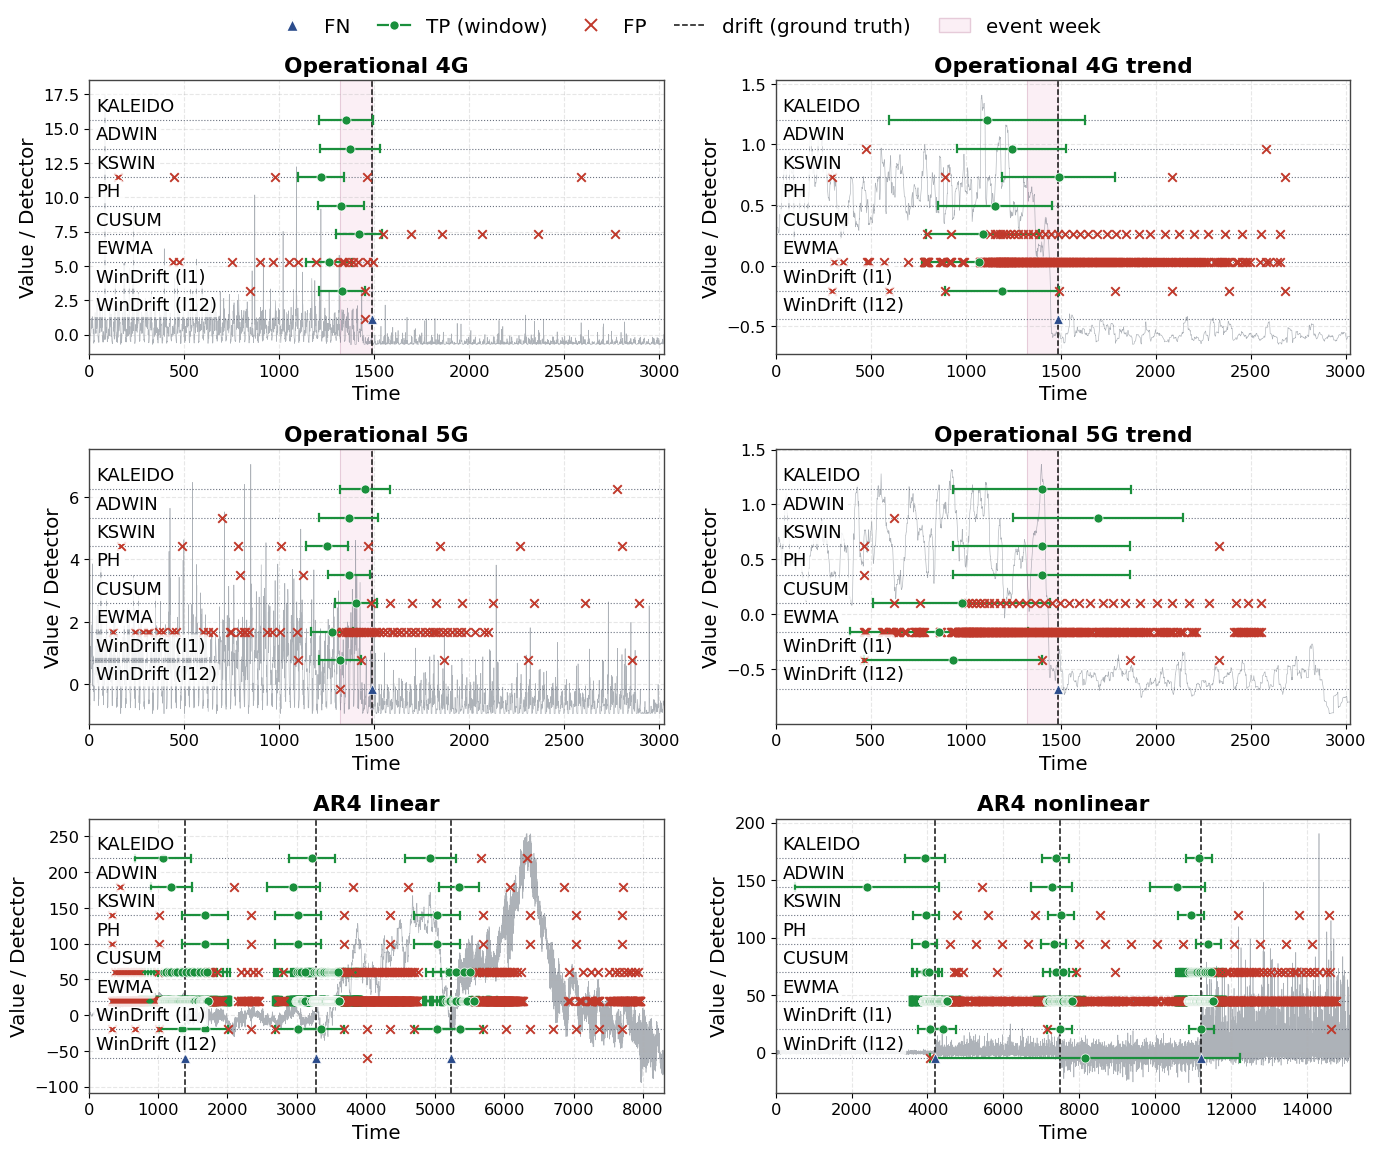

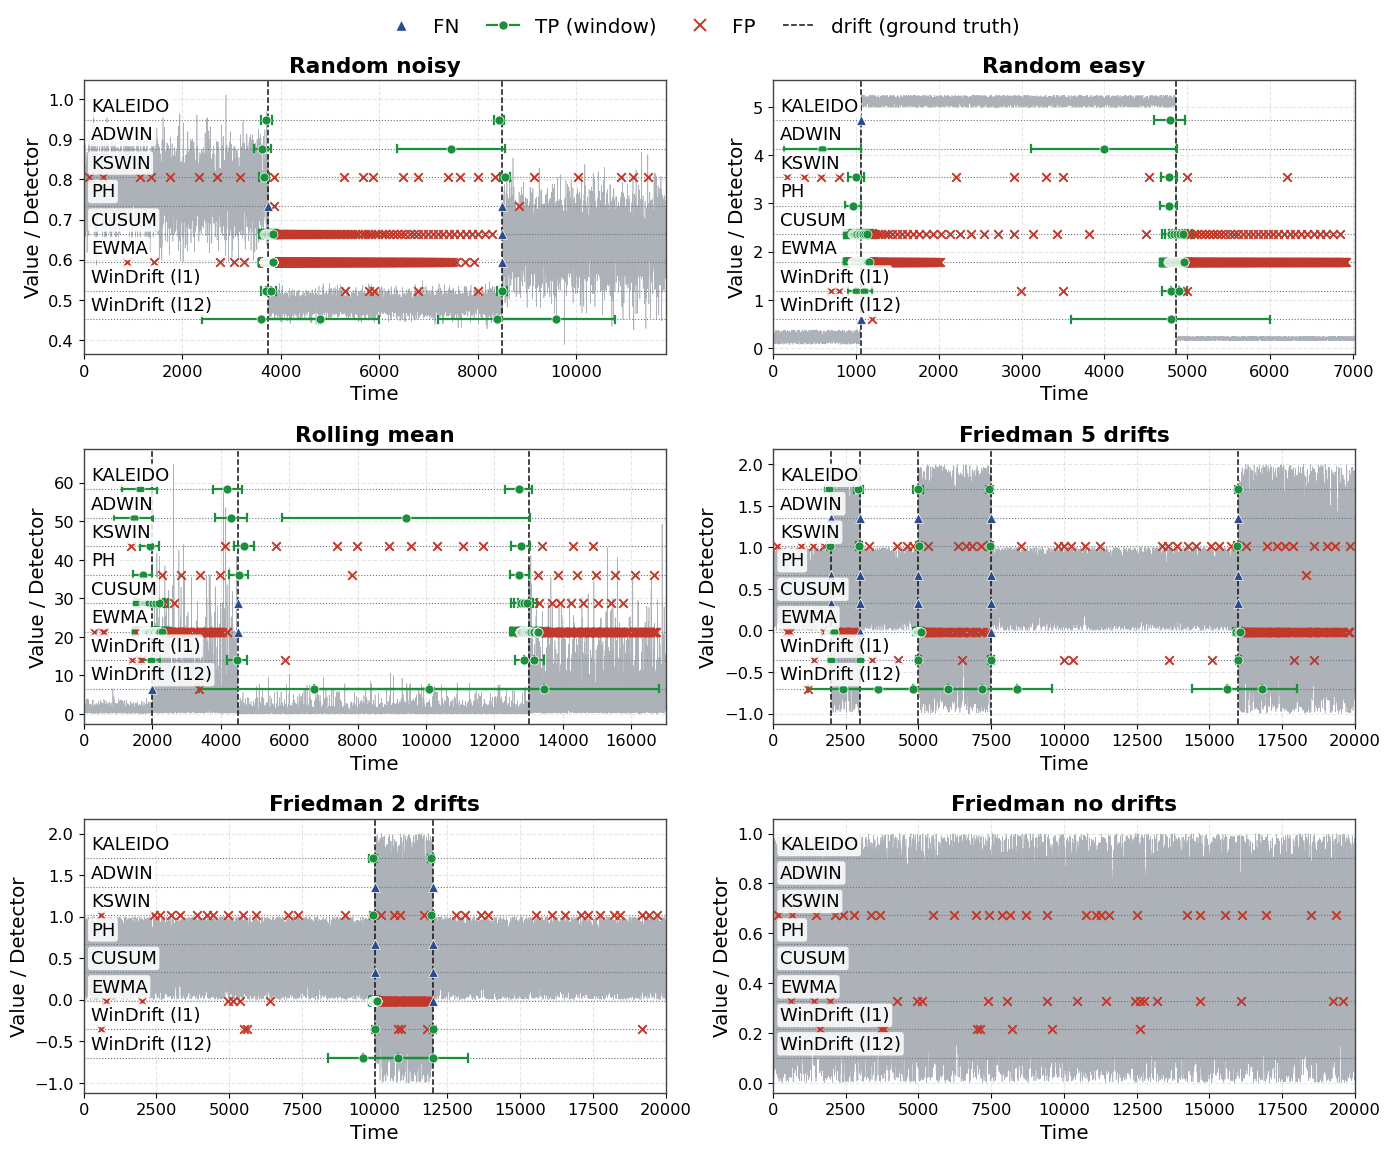

In [3]:
# ---- palette shared with the case-study and metric figures
SERIES_C = '#4b5563'                      # neutral dark slate for the data
GREY     = '#6b7280'                      # detector rows
OK_C, BAD_C = '#1a8f3c', '#c0392b'        # verdicts: TP = green, FP = red
FN_C     = '#2b4c8c'                      # missed drift = navy
DRIFT_C  = '#111111'                      # ground-truth drift
EVENT_BG = '#fbeff5'                      # event week (same tint as the "recent half" band)
EVENT_EC = '#e6cbd9'
OURS_BG  = '#ffffff'                      # band behind our detector's row (same as the metric plots)
BORDER   = '#444444'


def plot_examples(runs, save=None, ncols=3, panel_size=(7.0, 3.6), normalize=True,
                  fontsize=13,                   # axis labels
                  title_fontsize=None,           # panel titles                  (default fontsize+1)
                  tick_fontsize=None,            # tick numbers                  (default fontsize-2)
                  label_fontsize=None,           # detector names in the panels  (default fontsize-1.5)
                  legend_fontsize=None,          # legend                        (default fontsize)
                  font_scale=1.0,                # multiplies every text size; nothing else changes
                  text_color='black', bold_family='DejaVu Sans',
                  series_lw=0.45, series_alpha=0.45,
                  marker_scale=1.0, window_lw=1.6,
                  highlight_first=True,          # light-blue band behind the first (our) detector row
                  letter_titles=False,           # True -> '(a) Operational 4G'
                  legend_frame=True, detector_titles=DETECTOR_TITLES,
                  xlabel='Time', hspace=0.55, wspace=0.18):
    '''One panel per run, one row per detector (ours first, on a light-blue band). TP = circle at the window
    middle + capped bar over the window, FP = x, FN = triangle at the missed drift, drift = dashed line,
    event week shaded. Text uses DejaVu Sans; panel titles use `bold_family`. One legend on top.'''
    title_fontsize = title_fontsize or fontsize + 1
    tick_fontsize = tick_fontsize or fontsize - 2
    label_fontsize = label_fontsize or fontsize - 1.5
    legend_fontsize = legend_fontsize or fontsize
    fontsize, title_fontsize, tick_fontsize, label_fontsize, legend_fontsize = (
        v * font_scale for v in (fontsize, title_fontsize, tick_fontsize, label_fontsize, legend_fontsize))
    mpl.rcParams.update({
        'font.family': 'sans-serif', 'font.sans-serif': ['DejaVu Sans'],
        'mathtext.fontset': 'dejavusans', 'axes.formatter.use_mathtext': False,
        'pdf.fonttype': 42, 'ps.fonttype': 42,
        'font.size': fontsize, 'axes.labelsize': fontsize, 'axes.titlesize': title_fontsize,
        'xtick.labelsize': tick_fontsize, 'ytick.labelsize': tick_fontsize, 'legend.fontsize': legend_fontsize,
        'text.color': text_color, 'axes.labelcolor': text_color, 'axes.titlecolor': text_color,
        'xtick.color': text_color, 'ytick.color': text_color,
    })
    n = len(runs)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(panel_size[0] * ncols, panel_size[1] * nrows + 0.9), squeeze=False)
    fig.subplots_adjust(hspace=hspace, wspace=wspace)
    axes = axes.ravel()
    letters = 'abcdefghijklmnopqrstuvwxyz'

    for k, (key, run) in enumerate(runs.items()):
        ax = axes[k]
        y = np.asarray(run['stream'], dtype=float)
        if normalize:
            lo, hi = np.nanmin(y), np.nanmax(y)
            y = (y - lo) / (hi - lo) if hi > lo else y * 0
        ymin, ymax = (0, 1) if normalize else (np.nanmin(y), np.nanmax(y))
        span = ymax - ymin
        ax.plot(y, color=SERIES_C, lw=series_lw, alpha=series_alpha, zorder=1)
        ax.set_ylim(ymin - 0.04 * span, ymax + 0.06 * span)
        ax.set_xlim(0, len(y))

        # true drifts (+ event week for the operational data)
        for x in np.where(run['labels'] == 1)[0]:
            ax.axvline(x, color=DRIFT_C, ls='--', lw=1.1, zorder=2)
            if run['event_length'] is not None:
                ax.axvspan(x - run['event_length'], x, fc=EVENT_BG, ec=EVENT_EC, lw=0.8, zorder=0)

        # one row per detector, ours on top
        dets = list(run['results'].keys())
        rows = np.linspace(ymax - 0.10 * span, ymin + 0.10 * span, len(dets))
        step = (rows[0] - rows[1]) if len(rows) > 1 else 0.2 * span
        for i, (det, ry) in enumerate(zip(dets, rows)):
            r = run['results'][det]
            # if i == 0 and highlight_first:
            #     ax.axhspan(ry - 0.25 * step, ry + 0.75 * step, color=OURS_BG, alpha=0.6, lw=0, zorder=0)
            ax.axhline(ry, color=GREY, ls=':', lw=0.8, zorder=2)
            for mid, start, end in r['tp']:
                ax.plot([start, end], [ry, ry], color=OK_C, lw=window_lw, solid_capstyle='butt', zorder=3)
                for xx in (start, end):
                    ax.plot([xx, xx], [ry - 0.015 * span, ry + 0.015 * span], color=OK_C, lw=window_lw, zorder=3)
                ax.scatter(mid, ry, marker='o', s=42 * marker_scale, color=OK_C, ec='white', lw=0.5, zorder=5)
            for mid, start, end in r['fp']:
                ax.scatter(mid, ry, marker='x', s=38 * marker_scale, color=BAD_C, lw=1.4, zorder=4)
            for idx in r['fn']:
                ax.scatter(idx, ry, marker='^', s=48 * marker_scale, color=FN_C, ec='white', lw=0.5, zorder=5)
            name = detector_titles.get(det, det)
            ax.text(0.012 * len(y), ry + 0.02 * span, f"{name}",
                    fontsize=label_fontsize, color=text_color, ha='left', va='bottom', zorder=6,
                    bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.85))

        ax.set_title(f"({letters[k]}) {run['title']}" if letter_titles else run['title'],
                     fontfamily=bold_family, fontweight='bold', pad=6)
        ax.set_xlabel(xlabel)
        ax.set_ylabel('Value (norm.) / Detector' if normalize else 'Value / Detector')
        ax.grid(True, ls='--', alpha=0.3)
        for sp in ax.spines.values():                           # clear borders on all four sides
            sp.set_visible(True); sp.set_color(BORDER); sp.set_linewidth(1.0)

    for ax in axes[n:]:
        ax.axis('off')

    handles = [Line2D([], [], ls='', marker='^', color=FN_C, mec='white', ms=8, label='FN'),
               Line2D([], [], ls='-', marker='o', color=OK_C, mec='white', ms=7, lw=window_lw, label='TP (window)'),
               Line2D([], [], ls='', marker='x', color=BAD_C, ms=8, mew=1.4, label='FP'),
               Line2D([], [], ls='--', color=DRIFT_C, lw=1.1, label='drift (ground truth)')]
    if any(r['event_length'] is not None for r in runs.values()):
        handles.append(plt.Rectangle((0, 0), 1, 1, fc=EVENT_BG, ec=EVENT_EC, label='event week'))
    fig.legend(handles=handles, loc='upper center', ncols=len(handles), frameon=legend_frame,
               fontsize=legend_fontsize, edgecolor=BORDER, fancybox=False,
               handlelength=1.6, columnspacing=1.4, bbox_to_anchor=(0.5, 0.995))
    fig.tight_layout(rect=(0, 0, 1, 0.965))
    if save:
        fig.savefig(save, bbox_inches='tight', facecolor='white')

    plt.show()
    return fig, axes

items = list(runs.items())
half  = len(items) // 2                                   # 12 datasets -> 6 + 6 -> 3 rows x 2 columns each
runs_1, runs_2 = dict(items[:half]), dict(items[half:])

fig1, _ = plot_examples(runs_1, normalize=False, legend_frame=False, save="figures/examples_all_detectors_part1.pdf", ncols=2,
                        fontsize=11, label_fontsize=10, legend_fontsize=11, font_scale=1.3)
fig2, _ = plot_examples(runs_2, normalize=False, legend_frame=False, save="figures/examples_all_detectors_part2.pdf", ncols=2,
                        fontsize=11, label_fontsize=10, legend_fontsize=11, font_scale=1.3)

selected: ['Operational 4G', 'Operational 5G trend', 'AR4 linear', 'AR4 nonlinear', 'Random noisy', 'Friedman 5 drifts']


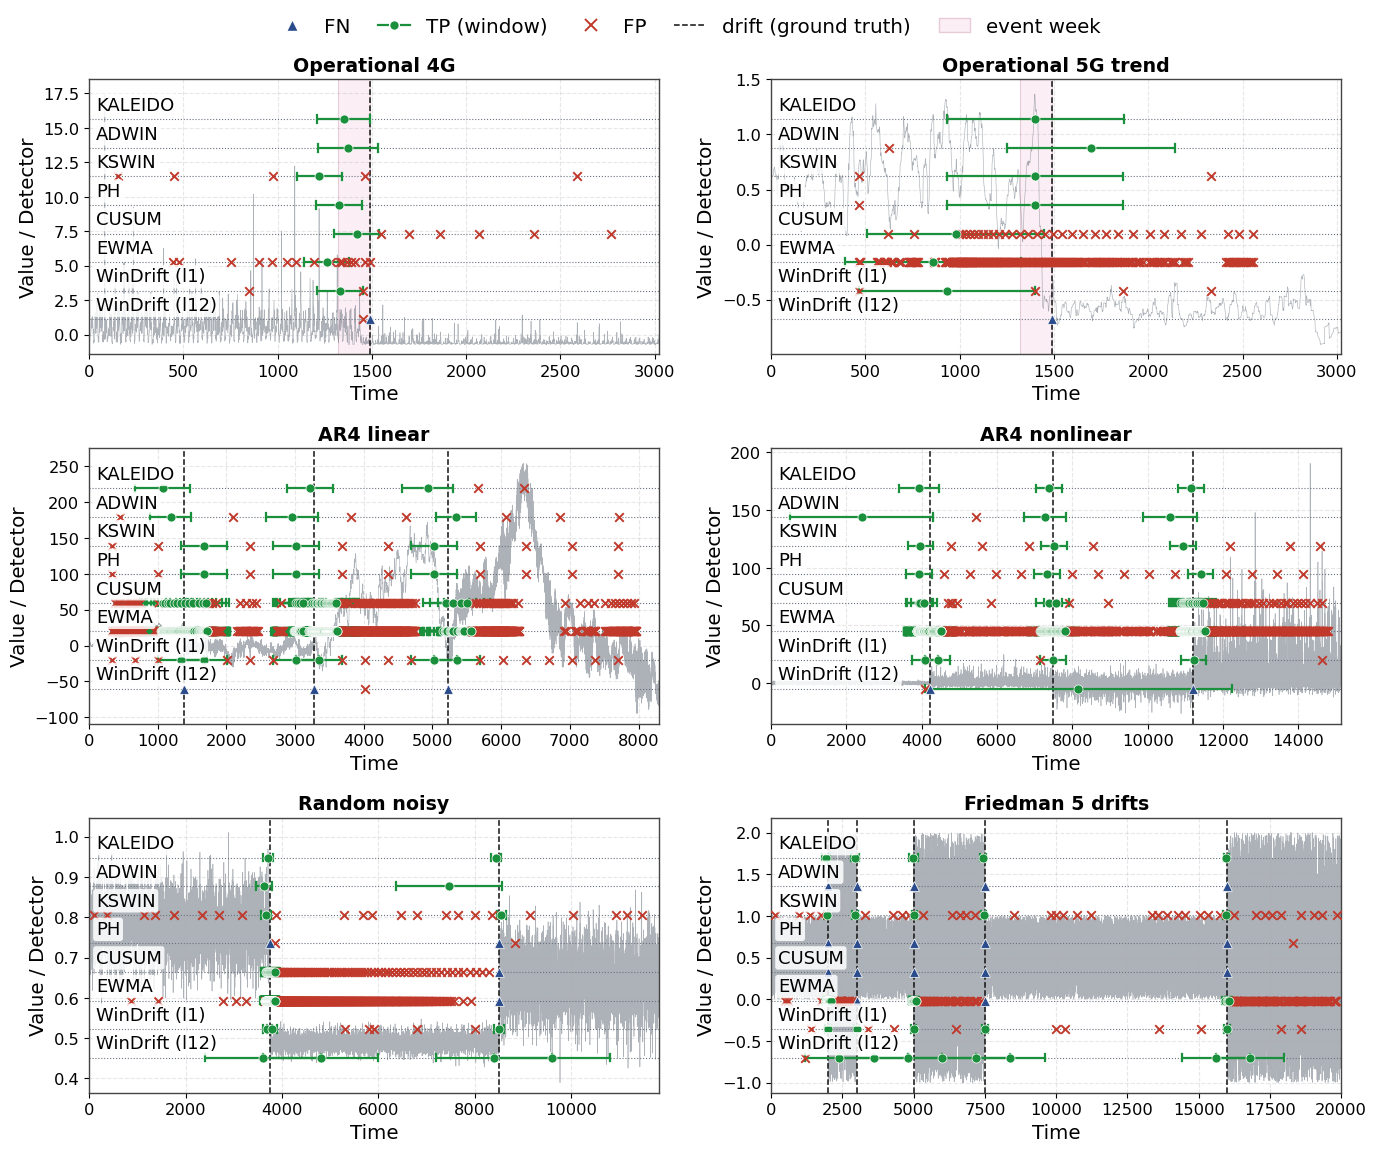

In [9]:
wanted = ['infocom_4G_add_hour#0', 'infocom_5G_add_hour_trend#0', 'AR4_linear_1#0',
          'AR4_nonlinear_1#0', 'random_noisy#0', 'friedman_5_drifts#0']

missing = [k for k in wanted if k not in runs]
assert not missing, f'not in runs: {missing} -- keys are {list(runs)}'
runs_3 = {k: runs[k] for k in wanted}              # keeps the order of `wanted`
print('selected:', [r['title'] for r in runs_3.values()])

fig3, _ = plot_examples(runs_3, normalize=False, legend_frame=False, save="figures/examples_selected_detectors.pdf", ncols=2,
                        fontsize=11, label_fontsize=10, legend_fontsize=11, title_fontsize=10.5, font_scale=1.3)